Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (28).csv
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No

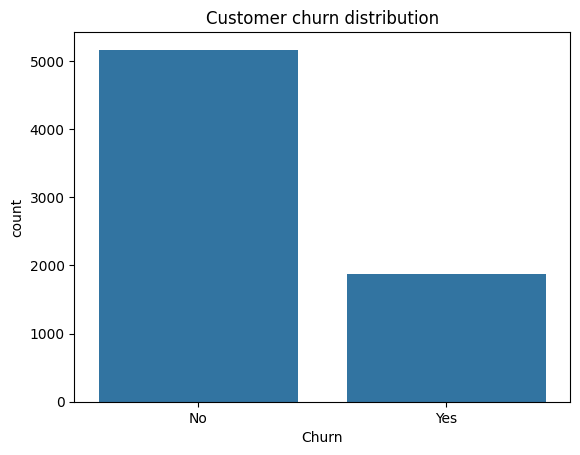

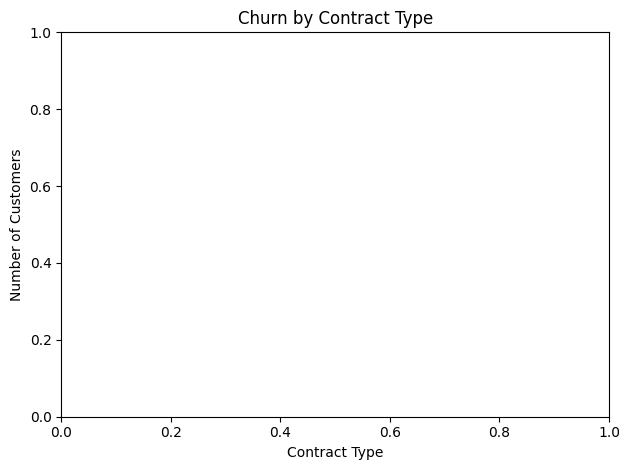

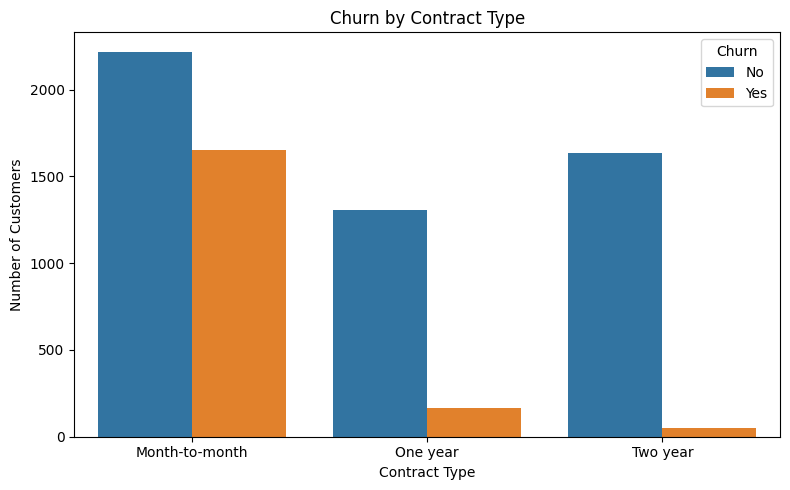

(7032, 2)
(7032,)
Categorical columns:
['Churn', 'customerID']

Numeric columns:
[]

X shape: (7032, 2)
y shape: (7032,)
Training data: (5625, 5627)
Testing data: (1407, 5627)
Training target: (5625,)
Testing target: (1407,)
Logistic Regression Accuracy: 100.0 %
Accuracy: 1.0

Confusion Matrix:
[[1033    0]
 [   0  374]]

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00      1033
         Yes       1.00      1.00      1.00       374

    accuracy                           1.00      1407
   macro avg       1.00      1.00      1.00      1407
weighted avg       1.00      1.00      1.00      1407

Confusion Matrix:
[[1033    0]
 [   0  374]]

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00      1033
         Yes       1.00      1.00      1.00       374

    accuracy                           1.00      1407
   macro avg       1.00      1.00      

/tmp/ipykernel_1284/1138074763.py:272: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  actual = pd.Series(y_test).replace({"No": 0, "Yes": 1}).astype(int)
/tmp/ipykernel_1284/1138074763.py:273: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  predicted = pd.Series(y_pred).replace({"No": 0, "Yes": 1}).astype(int)


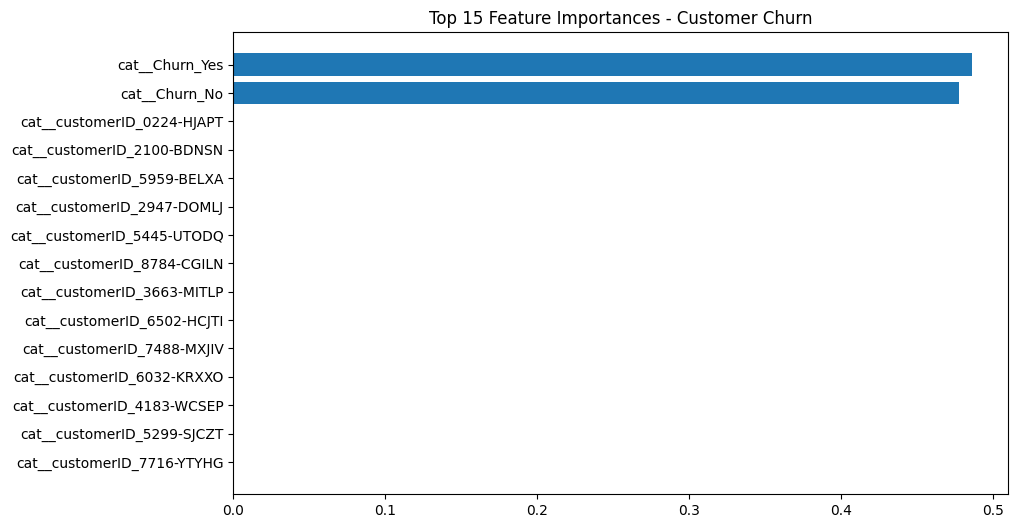

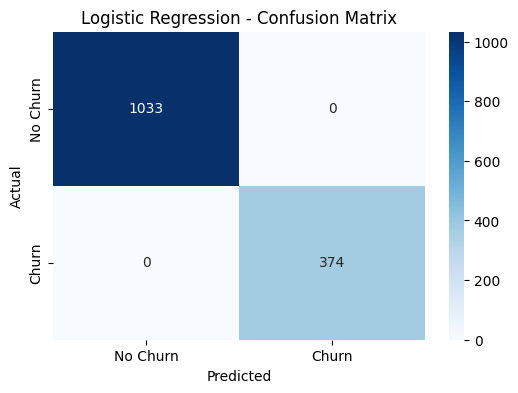

Classification Report:
              precision    recall  f1-score   support

    No Churn       1.00      1.00      1.00      1033
       Churn       1.00      1.00      1.00       374

    accuracy                           1.00      1407
   macro avg       1.00      1.00      1.00      1407
weighted avg       1.00      1.00      1.00      1407



In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
results = []


from google.colab import files
uploaded=files.upload()


df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

print(df.head())
print(df.shape)
print("Checking the  missing value")
print(df.isnull().sum())
print("Checking the duplicated ")
print(df.duplicated().sum())
print(df.info())
print("after")
print(df["TotalCharges"].isnull().sum())
print(df["Churn"].value_counts())
df=df.dropna(subset=["TotalCharges"].copy())
print("After the shape")
print(df.shape)
print("for making the graph")
sns.countplot(data=df,x="Churn")
plt.title("Customer churn distribution")
plt.show()
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()
X=df[["Churn","customerID"]]
Y=df["Churn"]
print(X.shape)
print(Y.shape)
# Text/categorical columns
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Numeric columns
numeric_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumeric columns:")
print(numeric_cols)

print("\nX shape:", X.shape)
print("y shape:", Y.shape)
X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

# Categorical columns encode aur missing values handle
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        ),
        (
            "num",
            SimpleImputer(strategy="median"),
            numeric_cols
        )
    ]
)

# Sirf training data par fit
X_train_encoded = preprocessor.fit_transform(X_train)

# Test data par sirf transform
X_test_encoded = preprocessor.transform(X_test)

print("Training data:", X_train_encoded.shape)
print("Testing data:", X_test_encoded.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)
model = LogisticRegression(max_iter=1000)

model.fit(X_train_encoded, y_train)

# Test data par predictions
y_pred = model.predict(X_test_encoded)

# Accuracy check
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_encoded, y_train)

rf_pred = rf_model.predict(X_test_encoded)

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))
for name, predictions in [
    ("Logistic Regression", y_pred),
    ("Random Forest", rf_pred)
]:
   for name, predictions in [
    ("Logistic Regression", y_pred),
    ("Random Forest", rf_pred)
]:
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 3),
        "Precision": round(
            precision_score(y_test, predictions, pos_label="Yes", zero_division=0), 3
        ),
        "Recall": round(
            recall_score(y_test, predictions, pos_label="Yes", zero_division=0), 3
        ),
        "F1-score": round(
            f1_score(y_test, predictions, pos_label="Yes", zero_division=0), 3
        )
    })

results_df = pd.DataFrame(results)
print(results_df)

results_df = pd.DataFrame(results)
print(results_df)
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Agar y mein "No"/"Yes" hain, to y ko isi tarah use kar sakte hain
cv_scores = cross_val_score(
    lr_pipeline,
    X,
    Y,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("F1 scores:", cv_scores)
print("Mean F1-score:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Model train karo
rf_pipeline.fit(X_train, y_train)

# Feature importance nikalo
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Top 15 features print karo
print("Top 15 Important Features:")
print(importance_df.head(15))

# Graph banao
top_features = importance_df.head(15).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Feature Importances - Customer Churn")
y_test_num = pd.Series(y_test).map({"No": 0, "Yes": 1}) if pd.Series(y_test).dtype == "object" else pd.Series(y_test)
y_pred_num = pd.Series(y_pred).map({"No": 0, "Yes": 1}) if pd.Series(y_pred).dtype == "object" else pd.Series(y_pred)
rf_pred_num = pd.Series(rf_pred).map({"No": 0, "Yes": 1}) if pd.Series(rf_pred).dtype == "object" else pd.Series(rf_pred)

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test_num, y_pred_num),
        accuracy_score(y_test_num, rf_pred_num)
    ],
    "Precision": [
        precision_score(y_test_num, y_pred_num, zero_division=0),
        precision_score(y_test_num, rf_pred_num, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_num, y_pred_num, zero_division=0),
        recall_score(y_test_num, rf_pred_num, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test_num, y_pred_num, zero_division=0),
        f1_score(y_test_num, rf_pred_num, zero_division=0)
    ]
})

print(results.round(3))

actual = pd.Series(y_test).replace({"No": 0, "Yes": 1}).astype(int)
predicted = pd.Series(y_pred).replace({"No": 0, "Yes": 1}).astype(int)

# Confusion Matrix
cm = confusion_matrix(actual, predicted, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(
    actual,
    predicted,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

